# Dimensionality-reduction benchmark

- **Question:** which low-dimensional representation (embedding) of the cells
  should every later stage build on?
- **Data:** the 38,430 annotated bone marrow cells from the core pipeline
  (Hay et al. 2018, eight donors, 19 fixed cell-type labels).
- **Design:** seven embeddings, everything else held constant — the same
  2,000 variable genes, 30 dimensions, 15 neighbours, Leiden resolution 1.0,
  the same UMAP settings and seed 7. Any difference below comes from the
  embedding alone.
- **Scoring:** `scib-metrics`, which asks two questions of each embedding: does
  it keep the cell types apart (biology), and does it mix the donors (batch).
- **Code:** `src/benchmark/`. This notebook only reads saved tables and
  figures; nothing is recomputed. Each figure links to its full-resolution
  file.

In [1]:
from io import BytesIO
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
MAX_PIXELS = 1600

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.precision", 3)


def show(figure: str, width: int = 900) -> None:
    """Saved figure, downscaled for display, with a link to the full file."""
    with PILImage.open(FIGURES / figure) as image:
        image.thumbnail((MAX_PIXELS, MAX_PIXELS * 4))
        buffer = BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(Image(data=buffer.getvalue(), format="jpeg", width=width),
            Markdown(f"[Full-resolution figure](../figures/{figure})"))


def table(name: str, **read_options) -> pd.DataFrame:
    """Saved results table, read from the results directory."""
    return pd.read_csv(RESULTS / name, **read_options)

## 1. The seven embeddings

| embedding | method | what it does | runtime |
|---|---|---|---|
| `pca` | PCA on log-normalised counts | the standard baseline | seconds |
| `pearson` | analytic Pearson residuals, then PCA | models count noise in closed form | seconds |
| `glmpca` | Poisson GLM-PCA on raw counts | models count noise by fitting | 1 h 47 min |
| `scvi` | variational autoencoder, donor as batch | the only one that removes donor effects inside the embedding | 9 min (GPU) |
| `diffmap_pca` | diffusion map built on `pca` | stretches the space along continuous paths | 54 s (both) |
| `diffmap_scvi` | diffusion map built on `scvi` | the same, on the donor-corrected base | |
| `cnmf` | consensus NMF, 30 programs, 20 repeats | each cell as a mix of gene programs | 24 min |

- **Why compare count models:** PCA assumes noise of the same size everywhere,
  but a gene averaging 500 counts varies far more than one averaging 5.
  `log1p` patches this; Pearson residuals and GLM-PCA model it directly; scVI
  learns it.
- **The two diffusion maps are not alternatives to the others.** They are built
  on top of `pca` and `scvi`, and are judged in the trajectory stage.
- **One non-default setting was needed: GLM-PCA `penalty = 10`.** The library
  default diverged within about four minutes ("deviance no longer finite")
  because very high-count genes such as HBB overflow under the Poisson log
  link. With the penalty it converged in 87 iterations.
- **Nothing was subsampled.** Platelet (103 cells) and T proliferating (47)
  would have shrunk too far to score label conservation.
- Runtimes were recorded at run time; neighbours, UMAP and Leiden for all seven
  took 4 min 52 s, and scoring 22 min 32 s (CPU, 4 jobs).

In [2]:
table("benchmark/benchmark_report/benchmark_report_embeddings.csv", index_col="embedding")

,dimensions,clusters
embedding,,
scvi,30,19
glmpca,30,20
pca,30,21
cnmf,30,31
pearson,30,33
diffmap_scvi,30,46
diffmap_pca,30,51


- **Every embedding is 38,430 cells × 30 dimensions**, so the comparison is
  like for like.
- **Clusters at the same Leiden resolution range from 19 to 51.** The count
  says how each embedding shapes the data, not how good it is.
- **`pca` gives 21 clusters**, the same 21 as the core pipeline, which used the
  same PCA settings — a consistency check that the benchmark rebuilt the same
  space.
- **`scvi` gives the fewest (19)**: it pulls neighbouring cell types together.
  That 19 equals the number of labels is a coincidence, not a match.
- **`pearson` (33) and `cnmf` (31) split the data more finely** than `pca`.
- **The diffusion maps split into 46 and 51 pieces.** They stretch the space
  along gradients, so a fixed resolution cuts them repeatedly. First sign that
  they are not peers for clustering.

## 2. Scores

**Biology — measured against the 19 cell-type labels**

- `Isolated labels`: are the rarest types kept separate.
- `KMeans NMI`, `KMeans ARI`: do k-means clusters agree with the labels.
- `Silhouette label`: is each type a tight, separate group.
- `cLISI`: are a cell's neighbours of the same type.

**Batch — measured against the eight donors**

- `BRAS`: within each cell type, are the donors mixed (silhouette-based).
- `iLISI`, `KBET`: is a cell's local neighbourhood a mix of donors in the
  overall proportions.
- `Graph connectivity`: is each cell type one connected piece rather than one
  piece per donor.

`Total` = 0.6 × biology + 0.4 × batch (checked: exact for all seven rows).

In [3]:
scores = table("benchmark/run_score/scib_scores.csv", index_col=0)
scores = scores.drop(index="Metric Type").astype(float)
scores.index = scores.index.str.removeprefix("X_")
scores.sort_values("Total", ascending=False).round(3)

,Isolated labels,KMeans NMI,KMeans ARI,Silhouette label,cLISI,BRAS,iLISI,KBET,Graph connectivity,Batch correction,Bio conservation,Total
Embedding,,,,,,,,,,,,
diffmap_pca,0.747,0.795,0.623,0.637,1.000,0.725,0.399,0.521,0.953,0.649,0.760,0.716
diffmap_scvi,0.499,0.774,0.648,0.692,0.999,0.762,0.488,0.673,0.858,0.695,0.723,0.712
cnmf,0.548,0.705,0.520,0.589,0.994,0.788,0.392,0.568,0.912,0.665,0.671,0.669
scvi,0.545,0.719,0.458,0.544,0.998,0.902,0.400,0.516,0.919,0.684,0.653,0.665
pca,0.600,0.787,0.599,0.567,1.000,0.854,0.277,0.382,0.877,0.598,0.710,0.665
pearson,0.470,0.725,0.618,0.578,0.999,0.804,0.332,0.472,0.917,0.631,0.678,0.659
glmpca,0.562,0.750,0.534,0.570,0.999,0.833,0.276,0.394,0.880,0.596,0.683,0.648


- **Everything is close.** The seven totals span 0.648 to 0.716 — 0.068 in
  all. `pca` (0.6653) and `scvi` (0.6654) tie to three decimals.
- **The two diffusion maps rank first and second** (0.716, 0.712), but they
  are derived from `pca` and `scvi`, not competitors to them (section 1).
- **Among the four genuine alternatives — `pca`, `pearson`, `glmpca`,
  `scvi` — `pca` has the best biology (0.710)**, ahead of `glmpca` 0.683,
  `pearson` 0.678 and `scvi` 0.653. It also has the highest NMI of the four
  (0.787).
- **`scvi` buys donor mixing with biology.** Best `BRAS` of all seven (0.902),
  but the lowest biology score and the lowest single biology value in the
  table, `KMeans ARI` 0.458.
- **The batch metrics disagree with each other about `pca`.** `BRAS` ranks it
  second (0.854); `iLISI` (0.277) and `KBET` (0.382) rank it last or near last.
  `BRAS` asks whether donors separate *within* a cell type; `iLISI` and `KBET`
  ask whether every neighbourhood holds donors in the overall proportions.
- **Those two metrics also punish uneven donor composition, not only technical
  batch.** Later stages showed the donors contributed very different cell
  mixes (T activated is 532 of 583 cells from MantonBM3; NK ranges from 54 to
  666 cells per donor). A neighbourhood of T activated cells cannot be
  donor-mixed in any embedding, so low `iLISI` and `KBET` here are partly
  composition, not a batch effect to correct.
- **`cLISI` carries no information:** 0.994 to 1.000 for all seven. It is
  ignored from here on.
- **`Isolated labels` favours `diffmap_pca` (0.747)**, with `pca` best of the
  four alternatives (0.600) and `pearson` worst of all (0.470).

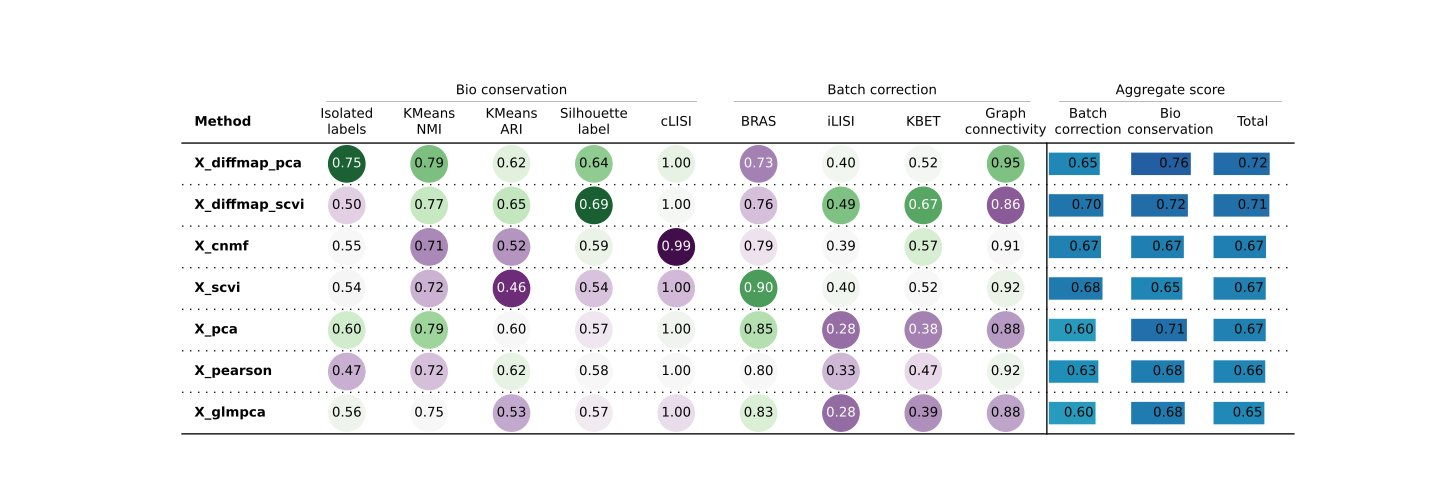

[Full-resolution figure](../figures/benchmark/run_score/scib_results.png)

In [4]:
show("benchmark/run_score/scib_results.png")

- **The figure is the `scib-metrics` standard table**, saved by the library at
  its own size (1,440 × 490 px); kept as it is.
- **Circle colours are relative within each column**: deep green is the best
  of the seven, deep purple the worst, whatever the gap. `cnmf`'s `cLISI` of
  0.99 shows as the darkest purple in the figure against six values of 1.00 —
  a difference of 0.006. Read the numbers, not the colours.
- **The aggregate bars are on a 0–1 scale**, so with totals inside a 0.068
  range they look nearly equal, which is the honest picture.

## 3. The biology–batch trade-off

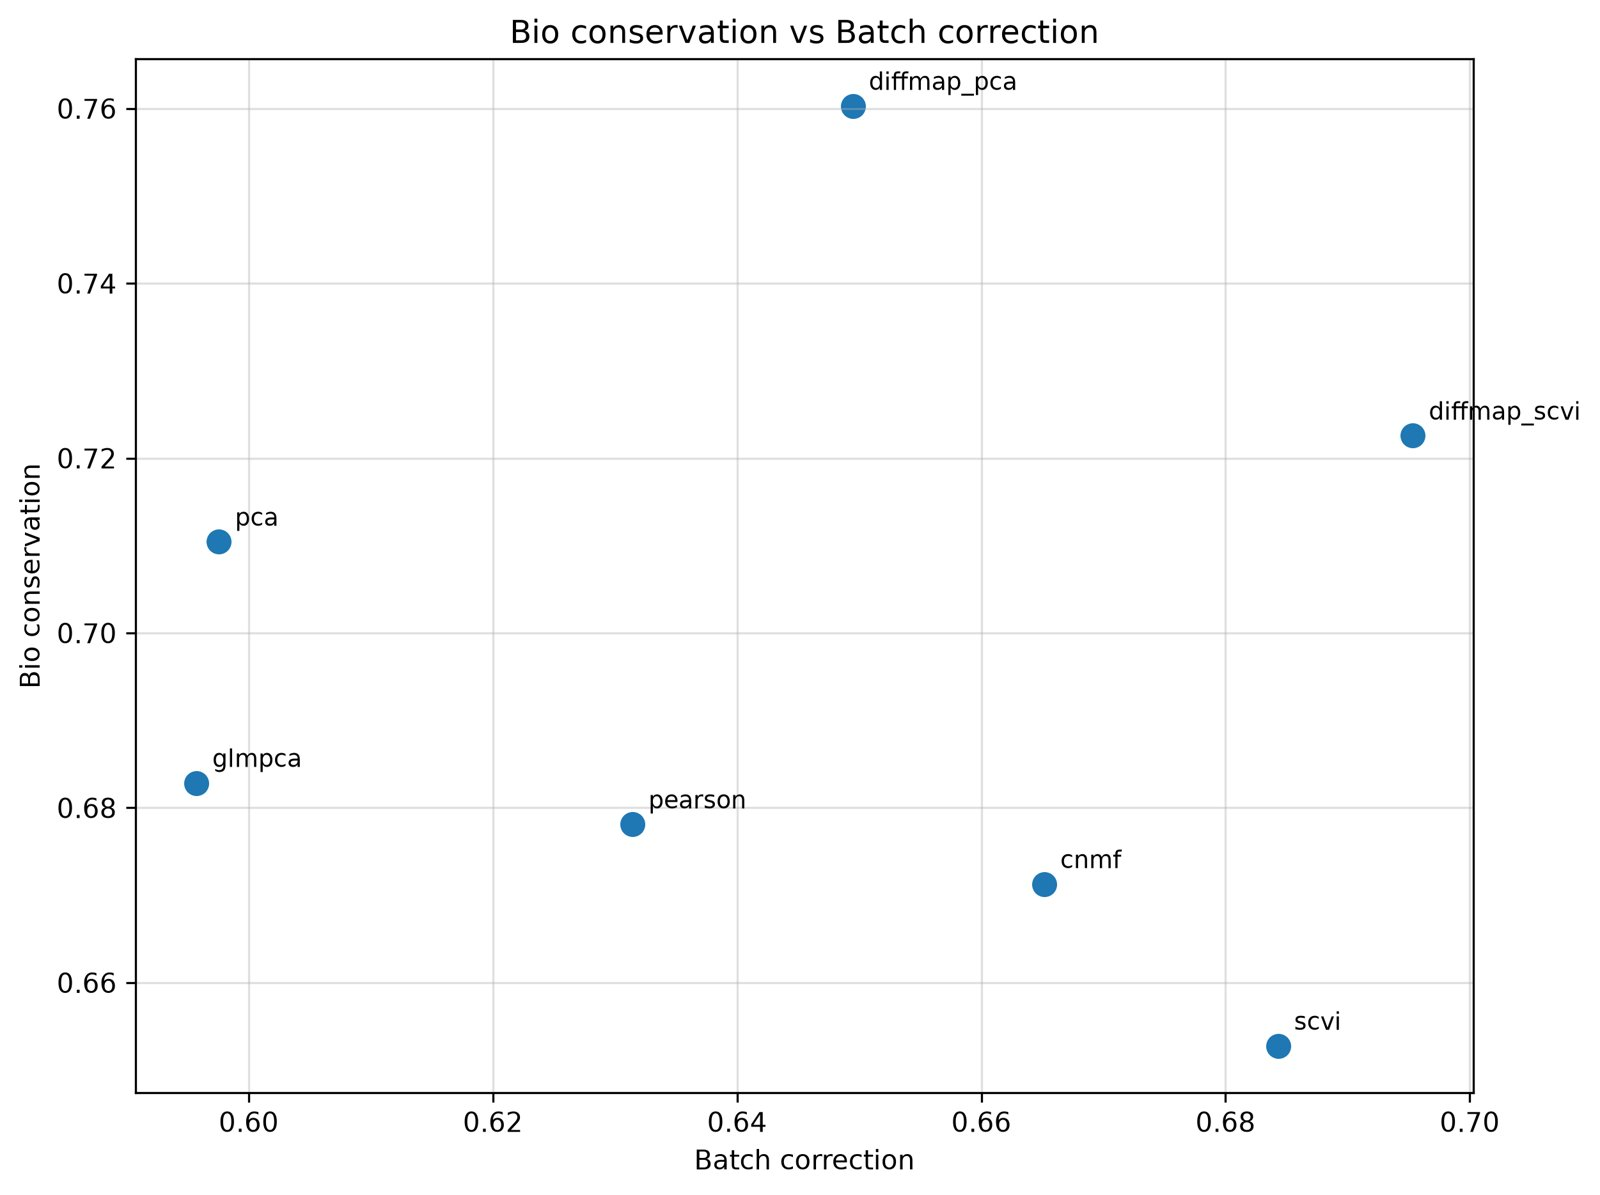

[Full-resolution figure](../figures/benchmark/benchmark_report/score_scatter.png)

In [5]:
show("benchmark/benchmark_report/score_scatter.png", width=700)

- **Without the two diffusion maps, the five remaining points fall on a
  downward line**: the more an embedding mixes donors, the less it keeps the
  cell types apart (Pearson r −0.86, Spearman −0.90 over the five).
- **`pca` sits top left, `scvi` bottom right**, with `pearson` and `cnmf`
  between them. `glmpca` sits below `pca` at the same batch score, so it is
  dominated by `pca` on both axes.
- **The axes are zoomed** (biology 0.65–0.76, batch 0.60–0.70). The slope is
  real, but every gap is a few hundredths.
- **`diffmap_pca` sits above the line** on both counts — the same caveat as in
  the score table: it is not an independent method.
- **Reading:** batch correction is bought with biology, and on a dataset with
  a weak donor effect that is a bad trade.

## 4. The same cells, seven ways

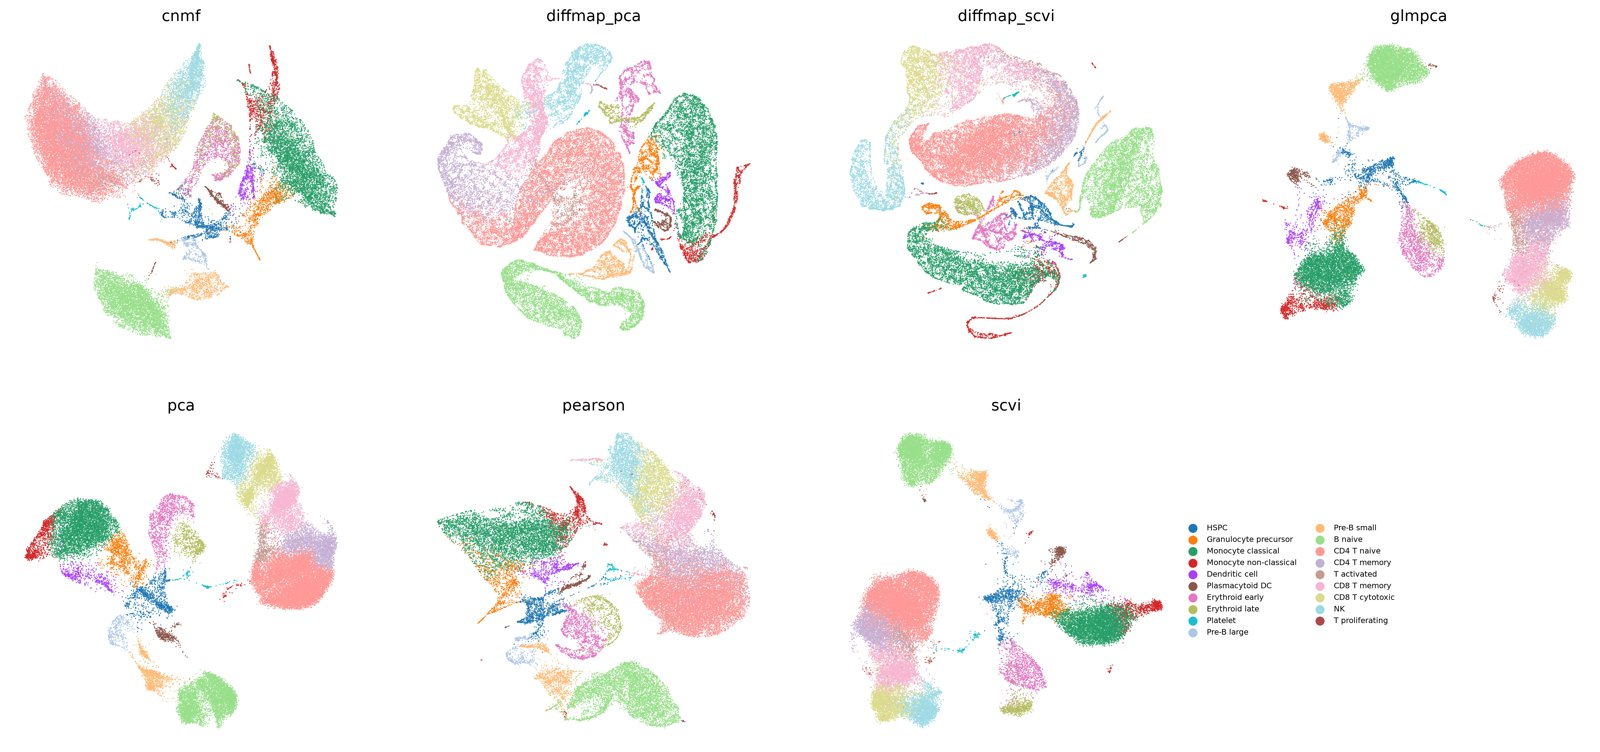

[Full-resolution figure](../figures/benchmark/benchmark_report/umap_grid_cell_type.png)

In [6]:
show("benchmark/benchmark_report/umap_grid_cell_type.png")

- **`pca` and `pearson` give the cleanest picture**: separate T, B, monocyte
  and erythroid islands, with the HSPC hub in the middle and thin bridges to
  each lineage.
- **`scvi` keeps the same main islands.** Its weaker biology score (ARI
  0.458) is not obvious at this scale; the score, not the picture, is the
  evidence for over-correction.
- **`glmpca` separates the main lineages but stretches the T region into one
  long column**, with the CD4, CD8 and NK labels stacked along it.
- **`cnmf` draws the T compartment as one wide continuous fan** (CD4 naive →
  memory → CD8 → NK), consistent with its biggest program spanning all T cells
  (section 5).
- **The diffusion maps are stringy and fragmented**: rings, threads and long
  arcs, matching their 46–51 clusters. Useful for paths, not for groups.
- **In every panel the rare types stay visible as small groups**, for
  example platelets (cyan) and plasmacytoid DCs (brown).

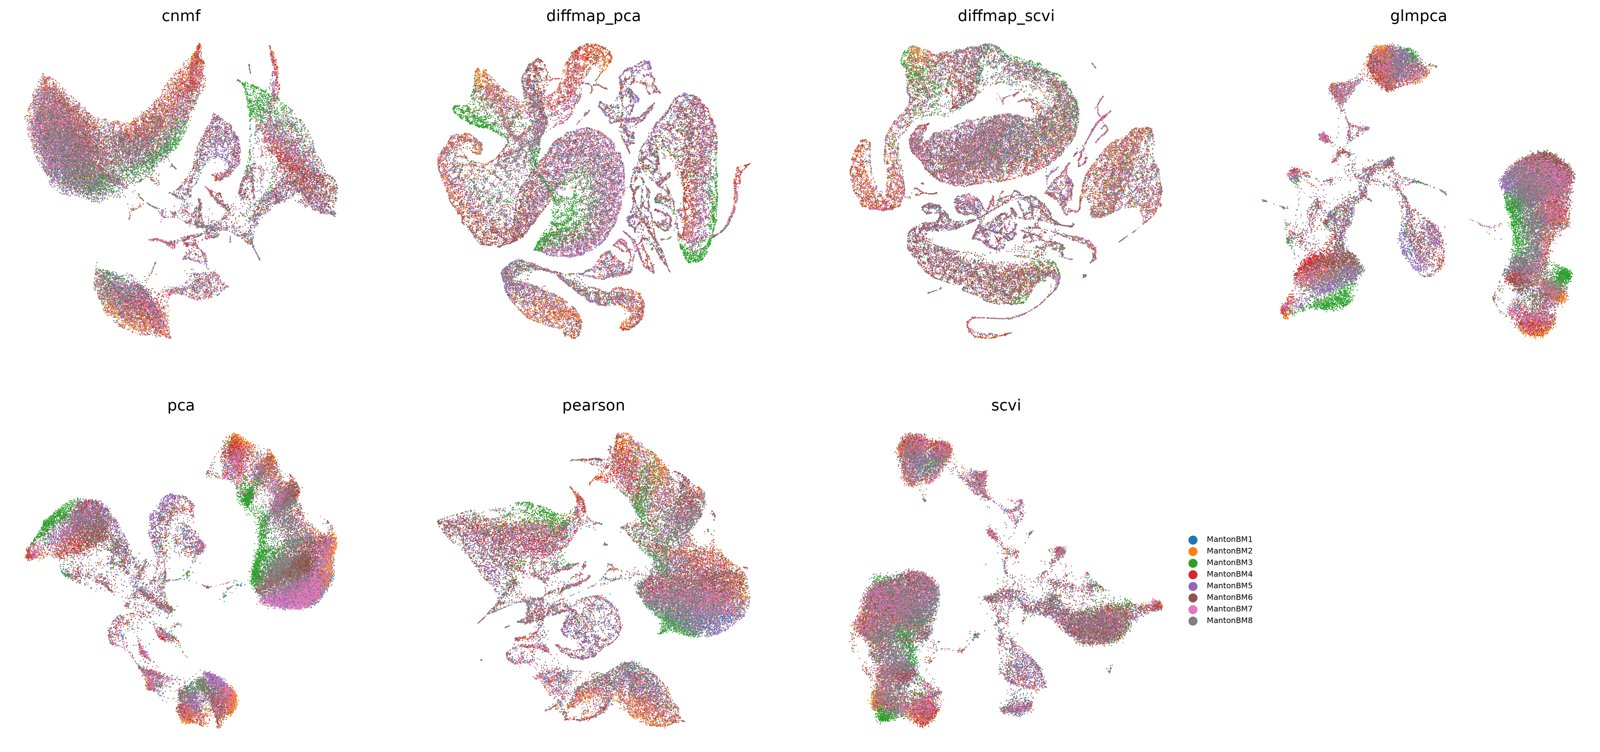

[Full-resolution figure](../figures/benchmark/benchmark_report/umap_grid_donor.png)

In [7]:
show("benchmark/benchmark_report/umap_grid_donor.png")

- **Donor colours are mixed through most of every panel.** No donor forms its
  own island in any embedding — the weak donor effect, drawn.
- **One donor stands out everywhere: MantonBM3 (green).** It forms a visible
  streak inside the T region in `pca`, `pearson` and `glmpca`, a band in the
  monocyte region, and separate green arcs in `diffmap_pca`. This matches
  what later stages measured: MantonBM3 holds 532 of the 583 T activated cells
  and 45% of the non-classical monocytes.
- **`scvi` mixes MantonBM3 best**, but some green remains at the bottom of its
  T region. It is removing composition as well as technical variation, which
  is part of why its biology score drops.
- **`glmpca` shows the strongest donor patches** (green and red blocks in the
  T and monocyte regions), consistent with its low batch score (0.596).
- **Smaller leanings** (MantonBM7, pink, inside the CD4 T naive region of `pca`)
  are minor and do not form their own islands.

## 5. cNMF: programs instead of clusters

- cNMF splits the counts into 30 gene programs and gives each cell a usage of
  every program. A cell is a mix of programs rather than a member of one
  cluster.
- It is judged here on whether the programs are real biology, not on the score
  table.
- **Columns:** `mean_share` — average share of a cell's usage;
  `peak_share` — the highest share any single cell gives the program;
  `cells_led` — cells whose largest program it is (sums to 38,430).

In [8]:
usage = table("benchmark/benchmark_report/benchmark_report_cnmf_usage.csv",
              index_col="program")
genes = table("benchmark/emb_cnmf/cnmf_top_genes.csv", index_col=0)
usage["top_genes"] = [", ".join(genes[str(program)].head(8)) for program in usage.index]
usage

,mean_share,peak_share,cells_led,top_genes
program,,,,
1,0.317,0.976,17064,"EEF1A1, IL32, RPS2, LTB, TMSB4X, LDHB, RPL37A, RPLP0"
2,0.089,0.996,5003,"S100A9, S100A8, FCN1, LYZ, CSTA, S100A12, VCAN, CD14"
3,0.091,0.918,5117,"CD79A, CD74, IGHM, HLA-DRA, MS4A1, HLA-DPA1, IGKC, HLA-DPB1"
4,0.092,0.988,4264,"NKG7, GNLY, GZMB, PRF1, CST7, KLRF1, FGFBP2, GZMA"
5,0.040,0.963,1221,"FAM178B, EPCAM, KCNH2, AHSP, NMU, BLVRB, PRDX2, HBB"
6,0.037,0.978,379,"APOC1, CNRIP1, PCAT18, CYTL1, MAP7, AC084033.3, EPCAM, GAL"
7,0.029,0.999,556,"FCER1A, CLEC10A, ENHO, CST3, CD1E, PKIB, HLA-DPA1, IDO1"
8,0.027,1.000,763,"IGLL1, STMN1, VPREB1, TUBA1B, HMGB1, PIMREG, NUSAP1, CD24"
9,0.030,1.000,754,"G0S2, CXCL8, MAFB, NAMPT, ZFP36L1, FTH1, SAT1, C15orf48"


**What the 30 programs are** (read from the top genes, cells led in brackets)

| kind | programs |
|---|---|
| **Cell identity (16)** | 2 classical monocyte (5,003) · 3 B cell with MHC class II (5,117) · 4 NK and cytotoxic T (4,264) · 5 early erythroid (1,221) · 6 erythroid–megakaryocyte progenitor: APOC1, CNRIP1, CYTL1, GATA1, TFR2, KLF1, ITGA2B (379) · 7 dendritic cell (556) · 8 cycling large pre-B (763) · 10 HSPC: SPINK2, AVP, CRHBP, CD34 (610) · 11 non-classical monocyte (552) · 14 granulocyte precursor (429) · 16 late erythroid (324) · 17 plasmacytoid DC (326) · 18 and 24 platelet (60, 54) · 19 pro-B / early B (290) · 20 megakaryocyte progenitor: ITGA2B, VWF, ANGPT1, MMRN1 (118) |
| **Translation axis (1)** | 1 — EEF1A1, RPS2, RPLP0 with IL32, LTB, TRBC1 (17,064) |
| **Activities (5)** | 9 inflammatory: G0S2, CXCL8, IL1B, CXCL2, NAMPT (754) · 12 histones with erythroid genes (69) · 13 DNA replication (217) · 15 heat shock (38) · 23 mitosis (61) |
| **Types missing from the 19 labels (3)** | 22 plasma cell: IGHA1, IGHG1, JCHAIN, MZB1 (36) · 28 mast cell / basophil: HDC, TPSAB1, CPA3, MS4A2, with eosinophil genes CLC, PRG2 (15) · 30 macrophage: C1QA, C1QB, CD5L, TIMD4 (25) |
| **Stromal (4)** | 25, 26 (CXCL12, LEPR — reticular niche cells), 27, 29 (DCN, LUM, COL1A2 — fibroblast) (7, 21, 7, 5) |
| **Unclear (1)** | 21 — CKB, CST3, CD68, MMP14, TCIRG1, SDC1 (45) |

- **Program 1 is the protein-making (translation) axis, not a T-cell
  program.** It leads 17,064 cells (44%) with a mean share of 0.32 because
  ribosomal and elongation genes are high in every cell; it mainly marks the
  large, resting T compartment. The pathway stage confirmed this reading
  (top term `rRNA Processing`). *Corrects the earlier description "T cell
  mixed with ribosomal genes".*
- **16 programs recover known cell types without being told the labels**,
  each leading roughly the number of cells its label holds (for example
  program 2: 5,003 cells against 5,030 classical monocytes; program 17: 326
  against 330 plasmacytoid DCs).
- **Program 6 is an erythroid–megakaryocyte progenitor state** (GATA1, KLF1,
  TFR2 together with ITGA2B and PRSS57), sitting between HSPC and the early
  erythroid program. *Missing from the earlier write-up.*
- **Activities ride alongside identity, mostly.** Programs 13 (DNA replication,
  peak 0.64), 23 (mitosis, 0.71) and 12 (histones, 0.85) never fully own a
  cell: a dividing cell is still mostly its cell type.
- **Two activity programs do own cells.** Program 9 (inflammatory) reaches a
  peak of 1.00 and leads 754 cells, and program 15 (heat shock) reaches 1.00 in
  38 cells. These are cells dominated by a stress or activation state, not just
  carrying it. *Corrects the earlier claim that activity programs never
  dominate a cell.*
- **Three rare cell types are missing from the 19 labels**: plasma cells,
  mast cells / basophils and macrophages. Each leads only 15–36 cells but peaks
  at 0.996–1.000 — a handful of cells almost entirely made of one program,
  which noise does not produce. They sit inside larger clusters.
- **Four stromal programs lead 40 cells in total**, with lower peaks
  (0.70–0.96). A mononuclear preparation should hold almost no stroma, so these
  are either a trace of real contaminating niche cells or weak programs.
- **Program 21 is unidentified.** CD68, TCIRG1 and MMP14 suggest an
  osteoclast-like myeloid state, but it peaks at only 0.60 and leads 45 cells.
  Not confirmed.

In [9]:
ora = table("pathway/ora_cnmf_programs/ora_cnmf_significant.csv")
best = ora.sort_values("Adjusted P-value").groupby("program").head(1)
best.set_index("program").sort_index()[["library", "Term", "Overlap", "Adjusted P-value"]]

,library,Term,Overlap,Adjusted P-value
program,,,,
program_01,Reactome,rRNA Processing,11/27,9.098e-06
program_02,Reactome,Neutrophil Degranulation,37/109,3.479e-21
program_03,GO_BP,Antigen Receptor-Mediated Signaling Pathway (GO:0050851),12/32,4.554e-06
program_04,KEGG,Natural killer cell mediated cytotoxicity,10/17,1.364e-07
program_05,Reactome,O2 CO2 Exchange in Erythrocytes,5/7,7.840e-04
program_06,KEGG,Sulfur metabolism,3/3,1.615e-02
program_07,KEGG,Viral myocarditis,9/15,7.209e-07
program_08,Reactome,"Cell Cycle, Mitotic",25/139,2.058e-06
program_09,Reactome,Neutrophil Degranulation,26/109,9.494e-10


- **Cross-check from the pathway stage:** each program's top 100 genes tested
  against GO, KEGG and Reactome. 27 of 30 programs have at least one
  significant term; the table shows the best one per program.
- **The activity programs are confirmed by name**: 13 `Cell Cycle` (58/163),
  23 `Cell Cycle, Mitotic` (52/139), 15 `Response To Unfolded Protein` (9/9).
- **Two of the three missing cell types are supported**: plasma cells (22,
  `FCGR Activation`, 14/19) and macrophages (30, KEGG `Cholesterol
  metabolism`, 5/9: APOE, CD36, APOC1, ANGPTL4, CETP — lipid handling, plus
  `Innate Immune System` as its second term). **Mast cells / basophils (28) have no
  significant term**; they rest on their marker genes alone.
- **Programs 10 (HSPC) and 17 (plasmacytoid DC) also have no term.** Gene-set
  catalogues describe processes, not stem or rare-cell identities.
- **Some top terms are misleading by name**: program 7 (dendritic cell) tops
  out at KEGG `Viral myocarditis` because that set holds the MHC class II
  genes (HLA-DR, -DP, -DQ);
  program 6's `Sulfur metabolism` rests on 3 genes. Read the genes, not the
  term name.
- **The stromal programs 25–27 share an IGF-binding-protein term** (13–16 of
  34 genes), which supports a real stromal origin rather than noise.

## 6. Caveats

- **The biology scores are partly circular for `pca`.** The 19 labels were
  made by clustering on PCA, so NMI and ARI partly grade PCA against its own
  clusters. Two things limit it: CellTypist agreed with 17 of the 19 labels
  without using PCA, and `pearson` and `glmpca`, which played no part in the
  labels, score within 0.03 of `pca` on biology. Read `pca` as *no worse than
  the alternatives*, not *clearly better*.
- **The batch metrics reward mixing that may not be possible** where donors
  contributed different cell types (section 2).
- **One run per method.** Seed-to-seed spread was not measured; gaps of a few
  hundredths should not be over-read.
- **Only 30 dimensions and one resolution were tested.** Other settings could
  change the order of close pairs.

## 7. Decision for subsequent processes

- **`X_pca` is the foundation embedding for every later stage**: best biology
  of the genuine alternatives, seconds to compute, nothing to tune, and the
  donor effect does not need correcting. This overturned the plan written
  before the data was seen ("use scVI if the batch effect dominates").
- **The other embeddings were kept for specific jobs:**

| embedding | used for | outcome |
|---|---|---|
| `pca` | clusters, labels, anything needing a representation | used throughout |
| `cnmf` | pathway stage: 30 ready-made, cluster-free gene sets | 27 of 30 programs matched a gene-set term |
| `diffmap_pca` | trajectory: main pseudotime | confirmed — the only space that ordered Erythroid early before Erythroid late |
| `diffmap_scvi` | trajectory: cross-check | inverted the erythroid order; one of its two runs failed |
| `scvi` | sensitivity check when a result looks donor-driven | not needed on its own; through `diffmap_scvi` its over-correction showed up as false links between lineages |

- **The 19 cell-type labels stay fixed.** Later stages may compute on another
  embedding but never re-cluster or re-annotate, so the stages stay comparable.
- **Three things carried forward:** GLM-PCA needs `penalty = 10` on this data;
  plasma cells, mast cells / basophils and macrophages are present but
  unlabelled; and T activated, later found to be 91% one donor, is the weakest
  of the 19 labels.